# Regional glacier decline

**Purpose.** The paper's regional analysis. From the per-glacier area time series that
`glacierview areas` produced for 1,085 glaciers, it estimates each region's rate of surface-area
decline two ways:

1. **Regional trend:** a log-linear fit of every glacier's annual area against year, with a
   glacier-level bootstrap for the confidence band.
2. **Per-glacier slopes:** each glacier's own log-linear change over its observed span, averaged with
   weights, with a bootstrap confidence interval.

It also measures how far each glacier's predicted area is from its GLIMS area in the training year.

## Reproducing the published numbers
Two quirks of the original notebook shape the published results. Both are kept by default, each
behind its own flag below.
- **Two glaciers were dropped.** A positional slice removed the first two glacier columns
  (`G007026E45991N`, Trient, and `G007045E45994N`), which is why the paper reports 1,083 glaciers.
- **The slope weights are inverted.** Each glacier is weighted by the share of years it is *missing*,
  so glaciers with more observations count less. The paper's text describes the opposite.
  `.agents/context/state.md` has the corrected figures.

The bootstrap is seeded, so reruns are identical. The published run wasn't seeded, so its confidence
intervals differ slightly in the last digits.

## Inputs
All committed, in `data/analysis/` (`config.ANALYSIS_DIR`):
- `areas_binary_05_filtered_smooth_f.xlsx`: monthly areas, one column per glacier.
- `geo_areas.csv`: each glacier's `geog_area_rollup`.
- `training_areas.csv` and `training_data_set.csv`: GLIMS areas and training scenes, for the error
  check.

## Outputs
Plots and printed statistics. Set `SAVE_DIR` to also write the figures; the published ones are in
`figures/regional-decline/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glacierview import config

REGIONS = ["South America", "Asia", "Europe", "North America", "Caucausus"]
PUBLISHED_DROPPED = ["G007026E45991N", "G007045E45994N"]
DROP_PUBLISHED_GLACIERS = True   # as published: 1,083 glaciers, not 1,085
INVERTED_WEIGHTS = True          # as published: weight by the share of years missing
SAVE_DIR = None              # e.g. config.FIGURES_DIR / "regional-decline"
rng = np.random.default_rng(0)

## Load

In [2]:
raw = pd.read_excel(config.ANALYSIS_DIR / "areas_binary_05_filtered_smooth_f.xlsx")
monthly = raw.drop(columns=["Dates", "Dates.1"]).set_index(pd.to_datetime(raw["Dates.1"]))
monthly = monthly[monthly.index.notna()]
annual = monthly.groupby(monthly.index.year).mean()
if DROP_PUBLISHED_GLACIERS:
    annual = annual.drop(columns=PUBLISHED_DROPPED)

geo = pd.read_csv(config.ANALYSIS_DIR / "geo_areas.csv")
region_of = geo.set_index("glac_id")["geog_area_rollup"]
glaciers_in = {r: [g for g in annual.columns if region_of.get(g) == r] for r in REGIONS}
print(f"{annual.shape[1]} glaciers, {annual.index.min()}-{annual.index.max()}")
pd.Series({r: len(g) for r, g in glaciers_in.items()}, name="glaciers")

1083 glaciers, 1979-2024


South America    249
Asia             270
Europe           197
North America    293
Caucausus         74
Name: glaciers, dtype: int64

## Error against the GLIMS area in the training year

Not used to filter the regional results: the published run computed it but never applied it.

,abs_error,rel_error_pct
count,251.000000,251.000000
mean,3.819526,18.223323
std,7.618750,23.777781
min,0.001299,0.043571
25%,0.253733,4.351668
50%,0.988554,10.187706
75%,3.939305,23.155768
max,76.152341,186.799811


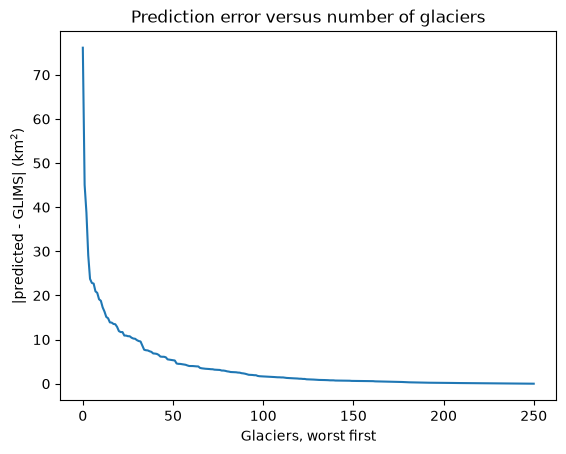

In [3]:
ids, areas = pd.read_csv(config.ANALYSIS_DIR / "training_areas.csv").iloc[:, 1:].to_numpy()
glims_area = pd.Series(areas.astype(float), index=ids)
scenes = pd.read_csv(config.ANALYSIS_DIR / "training_data_set.csv").drop_duplicates("glims_id")
year_of = scenes.set_index("glims_id")["file_name"].str[15:19].astype(int)

errors = pd.DataFrame([
    {"glims_id": g, "glims_area": glims_area[g], "predicted": annual.at[year_of[g], g]}
    for g in glims_area.index if g in annual.columns and g in year_of and year_of[g] in annual.index
]).dropna()
errors["abs_error"] = (errors["predicted"] - errors["glims_area"]).abs()
errors["rel_error_pct"] = 100 * errors["abs_error"] / errors["glims_area"]

ax = errors["abs_error"].sort_values(ascending=False, ignore_index=True).plot()
ax.set(title="Prediction error versus number of glaciers", xlabel="Glaciers, worst first",
       ylabel="|predicted - GLIMS| (km$^2$)")
errors[["abs_error", "rel_error_pct"]].describe()

## Regional trend: log-linear fit with a glacier bootstrap

South America: slope SE 0.0008, decline over the period -3.08%


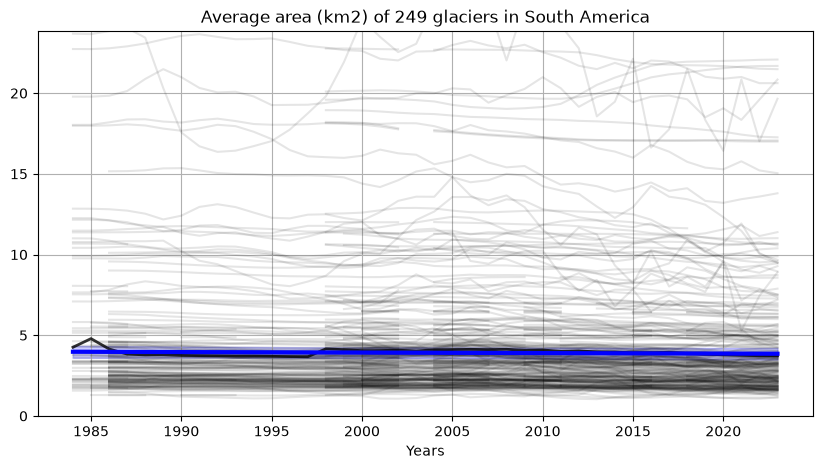

Asia: slope SE 0.0002, decline over the period -7.16%


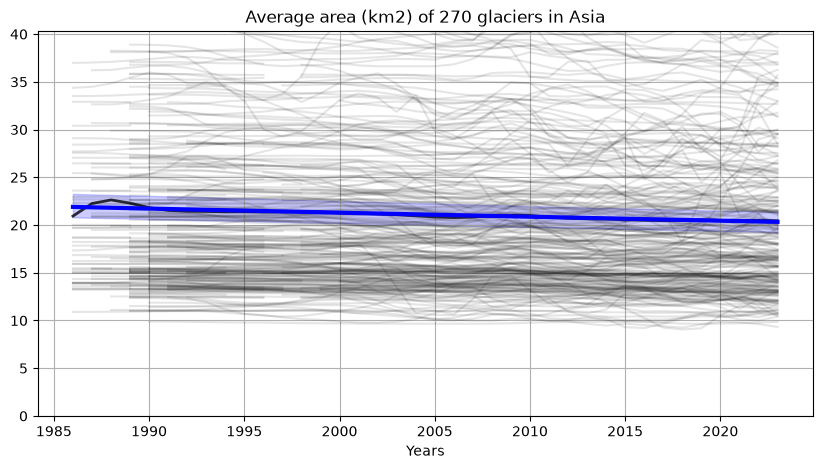

Europe: slope SE 0.0003, decline over the period -16.41%


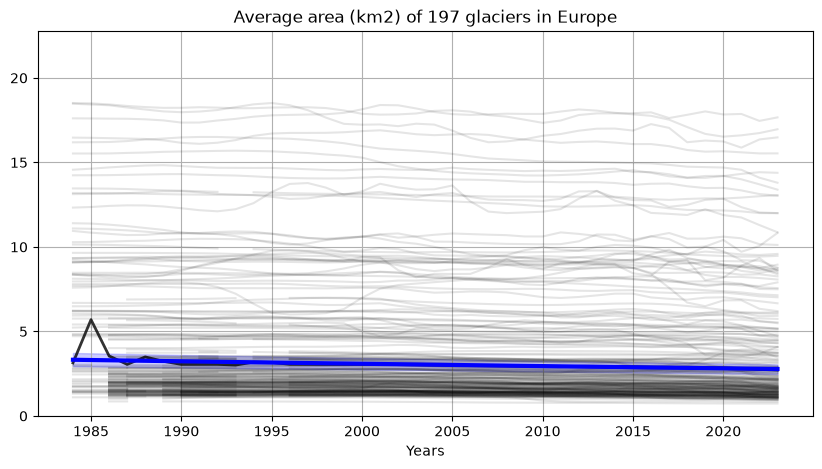

North America: slope SE 0.0010, decline over the period -2.80%


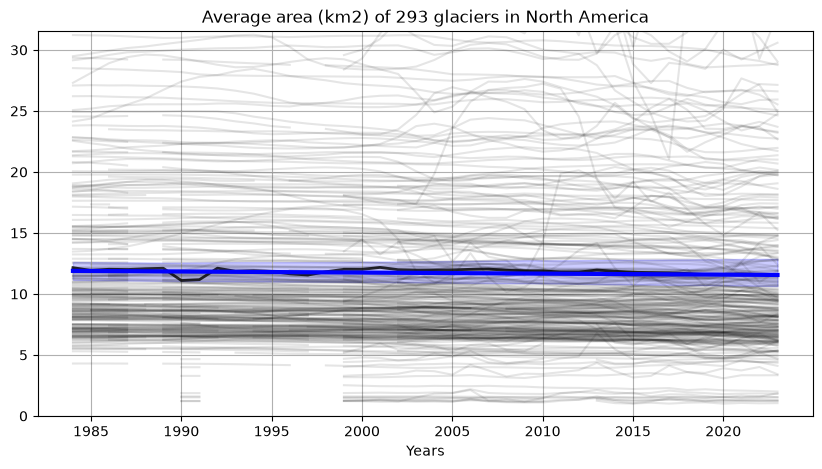

Caucausus: slope SE 0.0003, decline over the period -9.09%


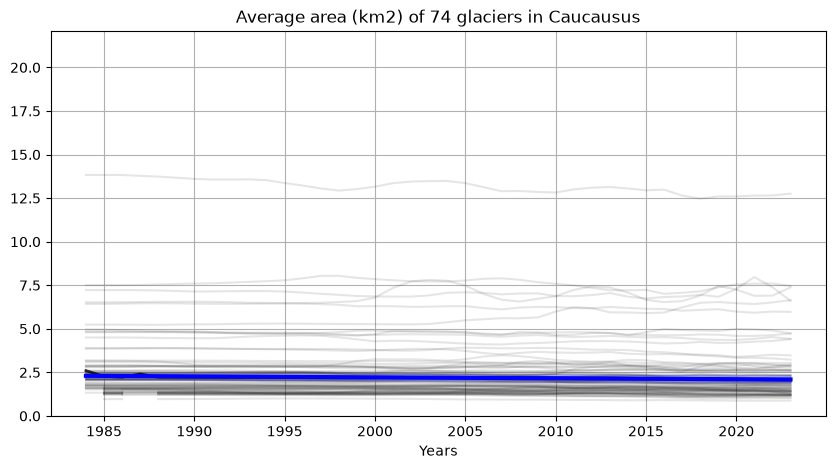

In [4]:
def bootstrap_trend(log_areas: pd.DataFrame, years: np.ndarray, n_iterations: int = 100) -> dict:
    """Fit log(area) ~ year to glaciers resampled with replacement."""
    values = log_areas.to_numpy()
    x = np.broadcast_to(log_areas.index.to_numpy(float)[:, None], values.shape)
    predictions, slopes = [], []
    for _ in range(n_iterations):
        pick = rng.integers(0, values.shape[1], values.shape[1])
        y, observed = values[:, pick], ~np.isnan(values[:, pick])
        if observed.sum() < 2:
            continue
        slope, intercept = np.polyfit(x[:, pick][observed], y[observed], 1)
        slopes.append(slope)
        predictions.append(intercept + slope * years)
    predictions = np.array(predictions)
    return {"mean": predictions.mean(axis=0), "ci": np.percentile(predictions, [2.5, 97.5], axis=0),
            "slope_se": np.std(slopes)}


total_decline = {}
for region, glaciers in glaciers_in.items():
    areas = annual[glaciers]
    years = areas.index[areas.notna().any(axis=1)].to_numpy()
    fit = bootstrap_trend(np.log(areas), years)
    trend, (low, high) = np.exp(fit["mean"]), np.exp(fit["ci"])
    total_decline[region] = (trend[-1] - trend[0]) / trend[0]
    print(f"{region}: slope SE {fit['slope_se']:.4f}, "
          f"decline over the period {total_decline[region]:.2%}")

    fig, ax = plt.subplots(figsize=(10, 5))
    areas.plot(ax=ax, alpha=0.1, legend=False, color="black")
    np.exp(np.log(areas).mean(axis=1)).dropna().plot(ax=ax, alpha=0.8, lw=2, color="black")
    ax.plot(years, trend, lw=3, color="blue", label="Regression line")
    ax.fill_between(years, low, high, color="blue", alpha=0.2, label="95% CI")
    ax.set(title=f"Average area (km2) of {len(glaciers)} glaciers in {region}", xlabel="Years",
           ylim=(0, trend.min() + 20))
    ax.grid(True)
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"{region.lower().replace(' ', '-')}-reg.png")
    plt.show()

## Per-glacier slopes
Each glacier's slope is its log-linear change over its own observed span, so `-0.1` is roughly a 10%
loss over the period.

South America: 249 glaciers, 51 positive slopes, weighted mean -0.08361, 95% CI [-0.1103, -0.0624], regional-trend decline -0.0308


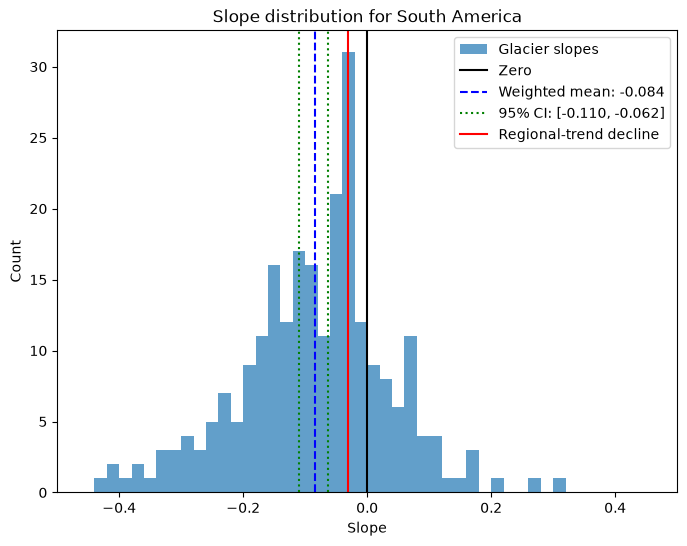

Asia: 270 glaciers, 45 positive slopes, weighted mean -0.05515, 95% CI [-0.0647, -0.0461], regional-trend decline -0.0716


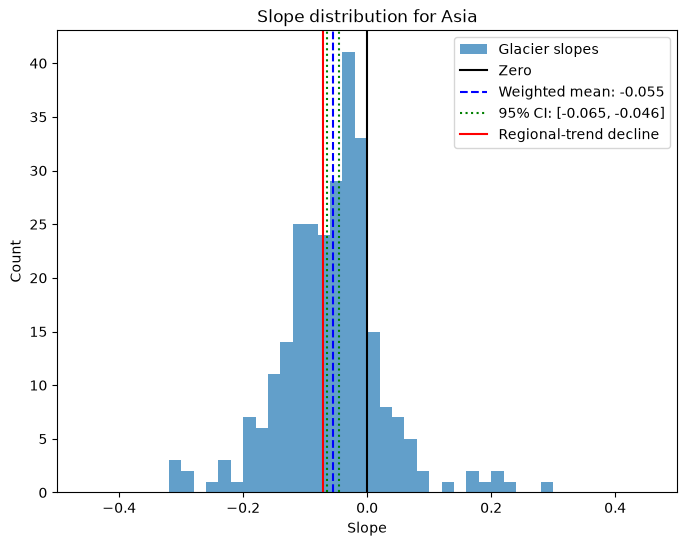

Europe: 197 glaciers, 24 positive slopes, weighted mean -0.10537, 95% CI [-0.1203, -0.0895], regional-trend decline -0.1641


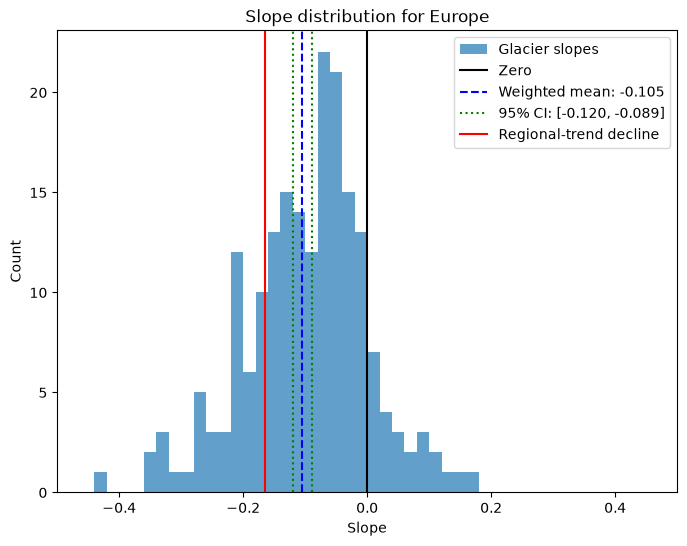

North America: 293 glaciers, 73 positive slopes, weighted mean -0.03979, 95% CI [-0.0562, -0.0240], regional-trend decline -0.0280


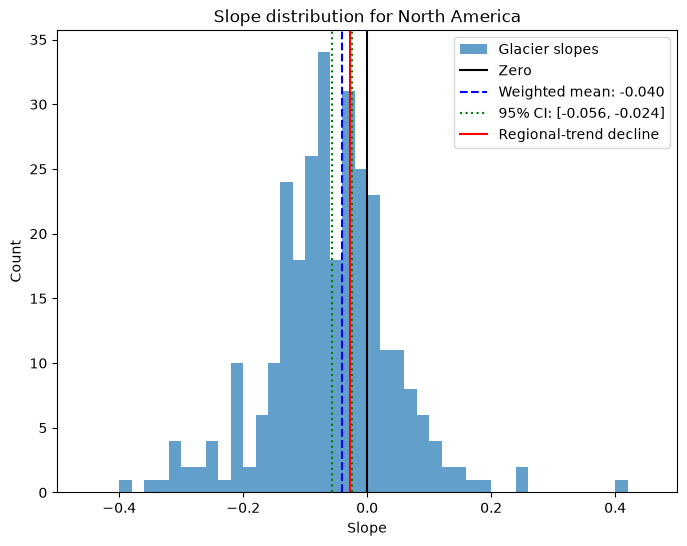

Caucausus: 74 glaciers, 12 positive slopes, weighted mean -0.06541, 95% CI [-0.0849, -0.0467], regional-trend decline -0.0909


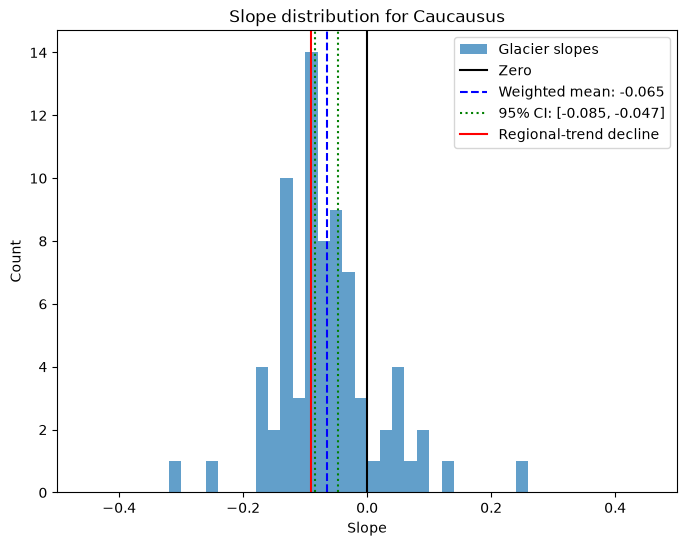

In [5]:
def glacier_slopes(areas: pd.DataFrame) -> pd.DataFrame:
    """Each glacier's log-linear change over its span, and its averaging weight."""
    rows = {}
    for glacier in areas.columns:
        series = np.log(areas[glacier]).dropna()
        if len(series) < 2:
            continue
        years = series.index.to_numpy(float)
        observed = len(series) / len(areas)
        rows[glacier] = {
            "slope": np.polyfit(years, series.to_numpy(), 1)[0] * (years.max() - years.min()),
            # Published: the share of years *missing*. Corrected: the share observed.
            "weight": 1 - observed if INVERTED_WEIGHTS else observed,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def bootstrap_mean(slopes: pd.DataFrame, n_glaciers: int, n_iterations: int = 500) -> np.ndarray:
    """Weighted mean slope over glaciers resampled with replacement.

    Resamples from all ``n_glaciers``, as the original did, then drops those
    with too few years to fit.
    """
    valid = np.r_[np.ones(len(slopes), bool), np.zeros(n_glaciers - len(slopes), bool)]
    values = np.r_[slopes["slope"], np.zeros(n_glaciers - len(slopes))]
    weights = np.r_[slopes["weight"], np.zeros(n_glaciers - len(slopes))]
    means = []
    for _ in range(n_iterations):
        pick = rng.integers(0, n_glaciers, n_glaciers)
        pick = pick[valid[pick]]
        if len(pick):
            means.append(np.average(values[pick], weights=weights[pick]))
    return np.array(means)


for region, glaciers in glaciers_in.items():
    slopes = glacier_slopes(annual[glaciers])
    mean = np.average(slopes["slope"], weights=slopes["weight"])
    low, high = np.percentile(bootstrap_mean(slopes, len(glaciers)), [2.5, 97.5])
    print(f"{region}: {len(glaciers)} glaciers, {(slopes['slope'] > 0).sum()} positive slopes, "
          f"weighted mean {mean:.5f}, 95% CI [{low:.4f}, {high:.4f}], "
          f"regional-trend decline {total_decline[region]:.4f}")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.hist(slopes["slope"], bins=50, range=(-0.5, 0.5), alpha=0.7, label="Glacier slopes")
    ax.axvline(0, color="black", label="Zero")
    ax.axvline(mean, color="blue", linestyle="--", label=f"Weighted mean: {mean:.3f}")
    ax.axvline(low, color="green", linestyle=":", label=f"95% CI: [{low:.3f}, {high:.3f}]")
    ax.axvline(high, color="green", linestyle=":")
    ax.axvline(total_decline[region], color="red", label="Regional-trend decline")
    ax.set(title=f"Slope distribution for {region}", xlabel="Slope", ylabel="Count",
           xlim=(-0.5, 0.5))
    ax.legend()
    if SAVE_DIR:
        fig.savefig(SAVE_DIR / f"{region.lower().replace(' ', '-')}-slopes.png")
    plt.show()